# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean().sort_values(ascending=False))

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
churn_date    0.88350
city          0.11725
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
reg_date      0.00000
plan          0.00000
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean().sort_values(ascending=False))


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
duration    0.55190
length      0.44740
date        0.00125
id          0.00000
user_id     0.00000
type        0.00000
dtype: float64


✍️ **Comentario**: 

- **churn_date** al tener el 88% de los valores ausentes, se ignorarán en nuestro análisis.
- **city** al tener un 11% de ausentes, se investigará más a fondo próximamente para imputar o dejarlos tal cual
- **duration** al tener 55% de ausentes, y ser una columna clave para el análisis, se analizará si eliminar o dejar como nulo.
- **lenght** es otra columna clave, y con un 44% de ausentes, se analizará si eliminar o dejar como nulo.
- **date** al tener 11% de ausentes, y no ser una columna clave para el análisis se dejará como nulo

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [13]:
(users['age'] == -999).sum()

55

- La columna `user_id` tiene 4,000 registros totales, empezando desde el 10 mil hasta el 13,999, por lo que no hay problema con esta columna
- La columna `age` hay sentinels con el valor mínimo (-999) que abordaremos después. La desviación estándar es considerable en esta columna. 

In [14]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [15]:
(usage['length'] == 0).sum()

133

In [16]:
(usage['duration'] == 0).sum()

15

- Las columnas `id` y `user_id`se miran normal, ya que sus valores mínimos y máximos se miran según sus registros totales.
- La columna `duration` tiene 15 llamadas con 0 minutos, lo consideramos como outliers que elimináremos. 
-  La columna `length` tiene 133 mensajes con 0 caracteres, lo cual claramente es un outlier a eliminar.

In [17]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


In [18]:
# ver los valores de hay en city
users['city'].unique()

array(['Medellín', '?', 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [19]:
# cuántos sentinels hay en city
(users['city'] == '?').sum()

96

- La columna `city` tiene 459 campos vacíos, 96 sentinels (?), los cuales son considerables pero no es una columna clave para responder las preguntas de negocios, por lo que imputaremos con 'unknown' a esos campos vacíos.
- La columna `plan` luce normal, con solo dos tipos de planes, donde la mayoría tiene contratado el plan básico.

In [20]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` observamos que los usuarios usan más texto que llamadas. 


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- Para **users**, la columna 'age' tiene sentinels con el valor mínimo (-999). Al ser una columna clave, imputaremos los 55 registros que hay con este valor con la mediana.
- Para **usage**, la columna 'duration', columna clave, eliminaremos los 15 outliers con 0 minutos.
- Para **usage**, la columna 'length', columna clave, eliminaremos los 133 outliers con 0 caracteres.
- Para **users**, la columna 'city', al no ser clave, pero al tener 459 faltantes, imputaremos con 'unknown' para no perder el resto de información. 


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [21]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc=True)
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   user_id     4000 non-null   int64              
 1   first_name  4000 non-null   object             
 2   last_name   4000 non-null   object             
 3   age         4000 non-null   int64              
 4   city        3531 non-null   object             
 5   reg_date    4000 non-null   datetime64[ns, UTC]
 6   plan        4000 non-null   object             
 7   churn_date  466 non-null    object             
dtypes: datetime64[ns, UTC](1), int64(2), object(5)
memory usage: 250.1+ KB


In [22]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce', utc=True)
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype              
---  ------    --------------  -----              
 0   id        40000 non-null  int64              
 1   user_id   40000 non-null  int64              
 2   type      40000 non-null  object             
 3   date      39950 non-null  datetime64[ns, UTC]
 4   duration  17924 non-null  float64            
 5   length    22104 non-null  float64            
dtypes: datetime64[ns, UTC](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


In [23]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

In [24]:
(users['reg_date'].dt.year == 2026).sum()

40

En `reg_date`, hay 40 registros imposibles con el año 2026

In [25]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()


array([2024.,   nan])

In [26]:
total = len(usage)
faltantes = usage['date'].isna().sum()
porcentaje = (faltantes / total) * 100

print(f"Total: {total}")
print(f"Faltantes: {faltantes}")
print(f"Porcentaje: {porcentaje}%")

Total: 40000
Faltantes: 50
Porcentaje: 0.125%


En `date`, solo encontramos datos del año 2024, el resto es NaN. Por lo que consideraremos solo el año 2024**

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- Del df **users** encontramos 40 datos imposibles del 2026, los cuales marcaremos como nan.
- Del df **usage** eliminaremos los datos de nan. 

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [27]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [28]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
(users['city'] == '?').sum()

0

In [29]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].where(users['reg_date'].dt.year <= 2024, pd.NA)

# Verificar cambios
(users['reg_date'] == 2026).sum()

0

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [30]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [31]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean().sort_values(ascending=False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Los nulos de `duration` son MAR (Missing At Random) ya que el 99% son mensajes de texto y los nulos de`length`el 99% son llamadas. 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [32]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [34]:
# Cuántos usuarios unicos hay en users y usage_agg
q_users = users['user_id'].nunique()
q_usage_agg = usage_agg['user_id'].nunique()
print('usarios en user_id', q_users)
print('usarios en usagge_agg', q_usage_agg)

usarios en user_id 4000
usarios en usagge_agg 3999


In [35]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [36]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[user_profile['reg_date'].dt.year == 2024][columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.000000,1330.000000
mean,48.414286,5.500000,4.557143,24.126669
std,17.963443,2.382293,2.140329,19.458620
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.332500
50%,48.000000,5.000000,4.000000,20.325000
75%,64.000000,7.000000,6.000000,32.542500
max,79.000000,16.000000,13.000000,155.690000


In [37]:
# Distribución porcentual del tipo de plan
user_profile[user_profile['reg_date'].dt.year == 2024]['plan'].value_counts(normalize=True)

Basico     0.656391
Premium    0.343609
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

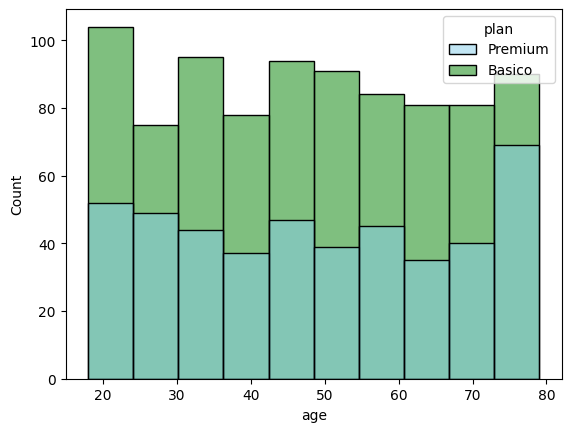

In [38]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='age', bins=10, hue='plan', palette=['skyblue','green'])
plt.show()


💡Insights: 
- La distribución con el plan premium es mayor en los adultos de 75-80 años y de los 45-50 años. No hay un sesgo aparente.
- La distribución con el plan básico es mayor con los jóvenes de 20-25 años, disminuye en los 25-30, para luego tener picos impredecibles. 

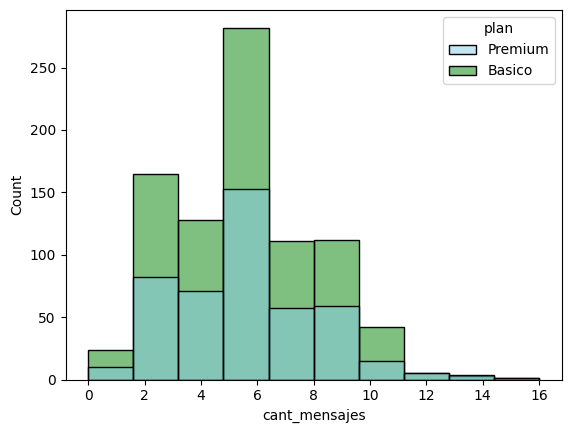

In [39]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='cant_mensajes', bins=10, hue='plan', palette=['skyblue','green'])
plt.show()


💡Insights: 
- Los usuarios de ambos planes tienen una distribución normal. Pero un pequeño grupo de usuarios del plan premium, aumenta fuertemente la cantidad de mensajes.

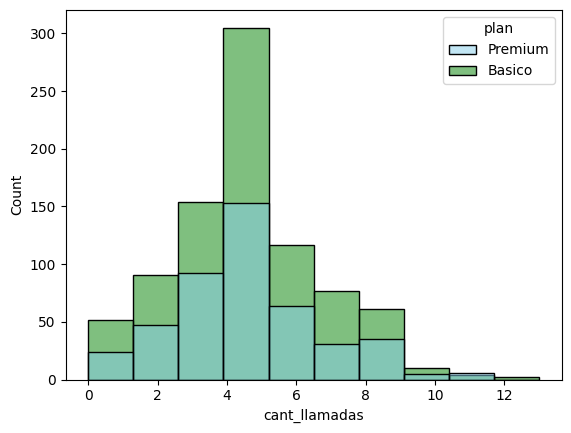

In [57]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='cant_llamadas', bins=10, hue='plan', palette=['skyblue','green'])
plt.show()

💡Insights: 
- Ambos planes tienen una distribución normal y predecible en cuanto a cantidad de llamadas.

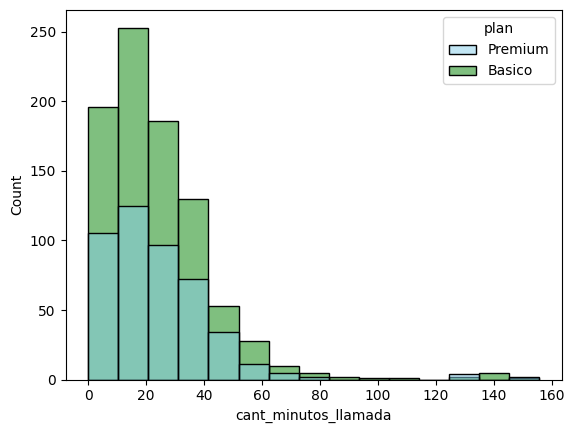

In [41]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='cant_minutos_llamada', bins=15, hue='plan', palette=['skyblue','green'])
plt.show()

💡Insights: 
- Ambos planes cuentan con sesgo a la derecha, lo cual se considera normal por la naturaleza del parámetro.
- Un pequeño grupo del plan premium tiene un alto número en cuanto a minutos de llamada.  

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

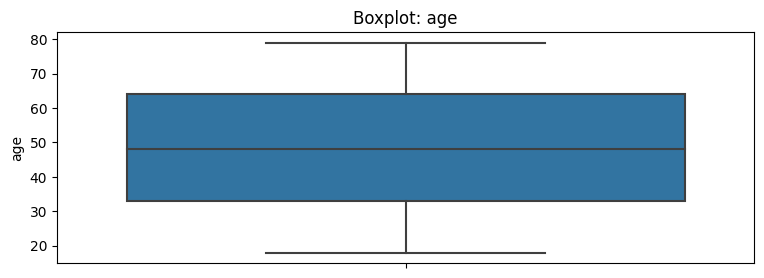

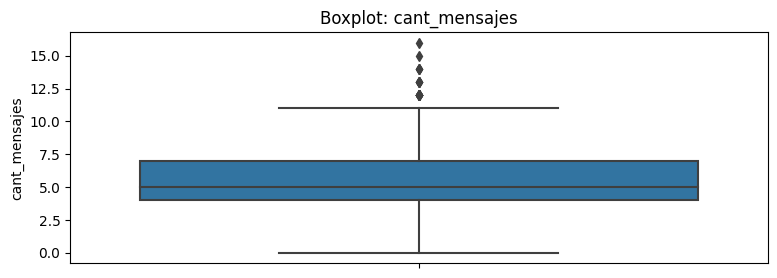

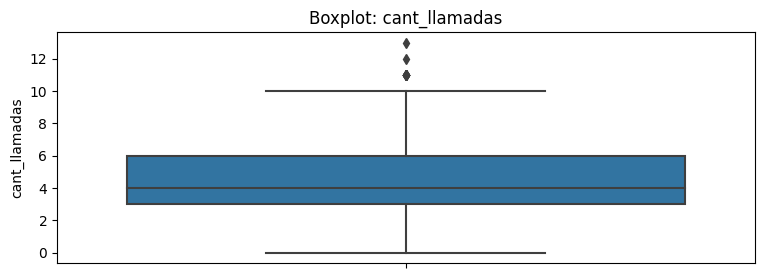

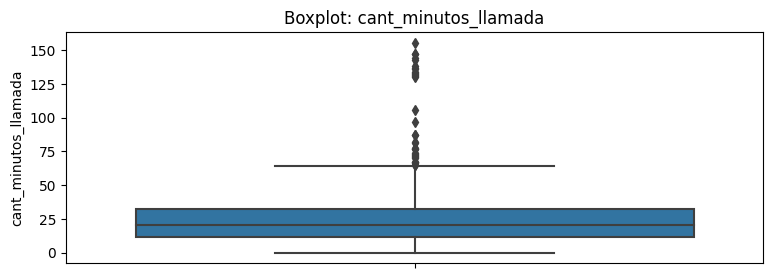

In [42]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(9,3))
    sns.boxplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], y=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- Age: No presenta outliers.
- cant_mensajes: Si presenta outliers. La mediana está en 5, cuando hay valores que van desde 12.5 a 15
- cant_llamadas: Presenta menos outliers que mensajes. La media está en 3.5, cuando hay valores que van desde 10 y 12. 
- cant_minutos_llamada: La que más outliers presenta. La media está cercana a 25, con valores que van desde 70 hasta 150. 

In [43]:

# Calcular límites con el método IQR

columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile_2024 = user_profile[user_profile['reg_date'].dt.year == 2024]

for col in columnas_limites:
    Q1 = user_profile_2024[col].quantile(0.25)
    Q3 = user_profile_2024[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_sup = Q3 + 1.5 *IQR
    outliers = user_profile_2024[user_profile_2024[col] > limite_sup]
    print(f"Columna: {col}")
    print(f"Límite superior: {limite_sup:.2f}")
    print(f"Cantidad de outliers: {len(outliers)}")
    print()


Columna: cant_mensajes
Límite superior: 11.50
Cantidad de outliers: 19

Columna: cant_llamadas
Límite superior: 10.50
Cantidad de outliers: 12

Columna: cant_minutos_llamada
Límite superior: 64.36
Cantidad de outliers: 34



In [44]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[user_profile['reg_date'].dt.year == 2024][columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,1330.000000,1330.000000,1330.000000
mean,5.500000,4.557143,24.126669
std,2.382293,2.140329,19.458620
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.332500
50%,5.000000,4.000000,20.325000
75%,7.000000,6.000000,32.542500
max,16.000000,13.000000,155.690000


💡Insights: 

- cant_mensajes: Mantendremos los outliers, ya que 16 mensajes en total cuando el límite está en 11.5 es un número realista, además de mantener a nuestros whales.
- cant_llamadas: Igualmente los mantendremos, ya que 13 llamadas en el año, cuando el límite está en 10.5, es viable.
- cant_minutos_llamada: Mantenemos, aunque hay mayor diferencia entre el máximo (155.69) y el límite (64), algunos de estos 34 son whales, lo cual es bueno para el negocio.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [46]:
# Crear columna grupo_uso

def categorizar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'uso medio'
    else:
        return 'alto uso'

user_profile['grupo_uso'] = user_profile.apply(categorizar_uso, axis=1)
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [47]:
# Crear columna grupo_edad
def categorizar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(categorizar_edad, axis=1)
user_profile.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

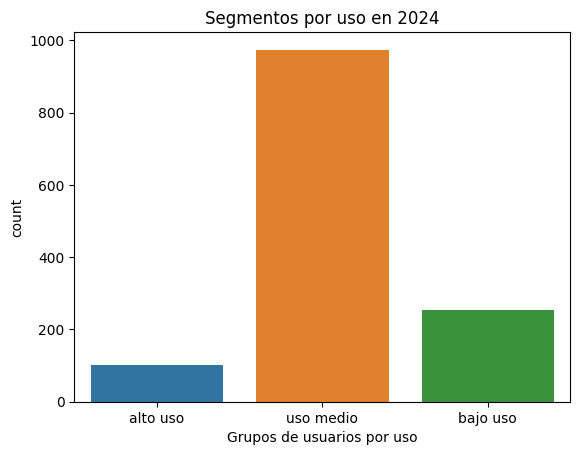

In [50]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='grupo_uso')
plt.xlabel('Grupos de usuarios por uso')
plt.title('Segmentos por uso en 2024')
plt.show()


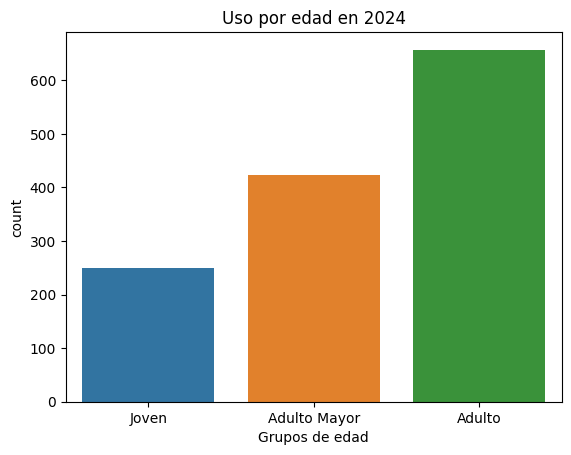

In [51]:

# Visualización de los segmentos por edad
sns.countplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='grupo_edad')
plt.xlabel('Grupos de edad')
plt.title('Uso por edad en 2024')
plt.show()


#Countplot para composición grupo de edad-plan
sns.countplot(data=user_profile[user_profile['reg_date'].dt.year == 2024], x='grupo_edad', hue='plan')
plt.title('Cantidad de clientes por plan y grupo de edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

**City** tenía el 11% de ausentes, por lo que se imputó sus ausentes y sus sentinels (?) con ‘unknown’. Para **Duration** y **length** se encontraron 15 y 133 valores en 0 respectivamente. Sin embargo, duration y length contaban con faltantes del tipo MAR (missing at random); duration (llamadas) tenía el 99% de sus ausentes en type=text y length (mensajes de texto) tenía el 99% en type=call, por lo que se dejaran estos datos.  
Reemplazamos los 55 sentinels de **age** (-999) con la mediana. Por otro lado, en el df users, contamos con 40 registros imposibles del **año** 2026, los cuales no fueron considerados. Sin embargo  en el df usage, solo hay datos del 2024, por lo que el análisis completo se centrará exclusivamente en ese año. 


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
La gran mayoría de los usuarios tienen un nivel de uso medio (menos de 10 mensajes y 10 llamadas al año). Mientras que por rango de edad, los adultos son los que más consumen de los servicios, seguido de los adultos mayores y por último los jóvenes. 
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
Los adultos de 31-59 años son el segmento que mayor uso hacen de los servicios de ConnectaTel.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Por la naturaleza de los servicios, llegué a la conclusión que los valores extremos que vienen de un solo lado, son viables:

Mensajes: El valor máximo  (16 ) en total cuando el límite está en 11.5 es un número realista. 
Llamadas: El valor máximo (13) llamadas en el año, cuando el límite está en 10.5, es viable.
Minutos de llamada: Encontramos 34 whales, que pasaron el límite marcado en 64 minutos, el máximo marcado en 155.69 minutos. 

**Todos estos valores extremos se mantuvieron en el análisis, ya que se tratan de clientes valiosos**. 

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Segmentar ofertas sobre el plan premium para los adultos de 31-59 años , ya que este segmento tiene la mayor diferencia entre plan básico y premium, además que en este grupo son más propensos a volverse whales. Incentivar con ofertas de minutos extra + mensajes a jovenes de -30 años, que son los que menos uso tienen. 

✍️ **Escribe aquí tu análisis ejecutivo:**

**Contexto**: Se analizaron los datos de consumo de llamadas, minutos/llamada y mensajes en el año 2024 de la empresa ConnectaTel. 

**Hallazgos**: Los hallazgos fueron los siguientes: 
1. ⚠️ Problemas detectados en los datos:
* La columna city contenía 11% de valores faltantes y sentinels, los cuales fueron imputados como 'unknown' para mantener la información de contexto.
* En age, se reemplazaron 55 valores sentinela (-999) con la mediana. Aunque se detectaron valores cero en duration (llamadas) y length (mensajes), estos se conservaron al ser Missing at Random (99% concentrados en sus tipos correspondientes).
* Se descartaron 40 registros del año 2026 en el dataset de usuarios. El análisis se concentra exclusivamente en datos de 2024, período con información completa y confiable para los 1,330 registros evaluados.

3. 🔍 Segmentos por Edad:
* Más de la mitad del uso total de los servicios, fueron generados por el grupo de adultos (31-59 años).
* Los jóvenes (<29 años) generaron solo 1/4 parte de los servicios. 

4. 📊 Segmentos por Nivel de Uso:
* Casi 3/4 partes de los usuarios, tienen un uso medio (< 10 mensajes/llamadas) al año.
* Menos de 1/4 un uso bajo (< 5 mensajes/llamadas) al año. 


➡️ **Sugerencias**
* Es conveniente ofertar plan premium a los adultos de 31-59 años para aumentar la cantidad de whales. 
* Ofertar minutos/mensajes extras a jovenes menores de 30 años con el fin de que abarquen más proporción en la cantidad de uso por segmento. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`